# Load forecast: results and error analysis

Run `fetch_data.py`, `clean.py` and `run_forecast.py` first. This notebook only reads their outputs.

In [1]:
import pandas as pd, json
from IPython.display import Image, display
pd.options.display.float_format = '{:,.3f}'.format
metrics = pd.read_csv('results/metrics.csv', index_col=0)
metrics.T

,baseline_168h,operator_DF,ridge,hgb
backtest_MAE,"1,511.740",461.082,889.066,736.183
holdout_MAE,"1,723.965",441.280,991.815,840.036
backtest_MAPE_%,8.519,2.643,5.235,4.273
holdout_MAPE_%,10.028,2.538,5.888,4.864
backtest_RMSE,"1,963.402",568.146,"1,142.190",983.525
holdout_RMSE,"2,205.743",553.836,"1,290.149","1,160.081"
backtest_MAE_top5%_hours,"3,779.565",916.805,"1,377.130","1,437.367"
holdout_MAE_top5%_hours,"2,753.552",705.216,"1,435.125","1,351.563"
skill_vs_168h_backtest,0.000,0.695,0.412,0.513
skill_vs_168h_holdout,0.000,0.744,0.425,0.513


## Data quality and timezone check

{
  "demand": {
    "expected_hours": 42075,
    "missing_hours": 0,
    "nonpositive_values": 11,
    "spikes": 0,
    "interpolated_hours": 8,
    "remaining_missing_hours": 3
  },
  "operator_forecast": {
    "expected_hours": 42075,
    "missing_hours": 96,
    "nonpositive_values": 115,
    "spikes": 0,
    "interpolated_hours": 0,
    "remaining_missing_hours": 211
  },
  "temperature": {
    "expected_hours": 42075,
    "missing_hours": 3,
    "nonpositive_values": 0,
    "spikes": 2,
    "interpolated_hours": 2,
    "remaining_missing_hours": 3
  },
  "first_hour_utc": "2022-01-01 00:00:00+00:00",
  "last_hour_utc": "2026-10-20 02:00:00+00:00",
  "operator_forecast_coverage": 0.9949851455733809,
  "timezone_check": {
    "local_min_hour": 4,
    "local_peak_hour": 19,
    "shape_ok": true,
    "utc_min_hour": 9,
    "utc_peak_hour": 23
  }
}


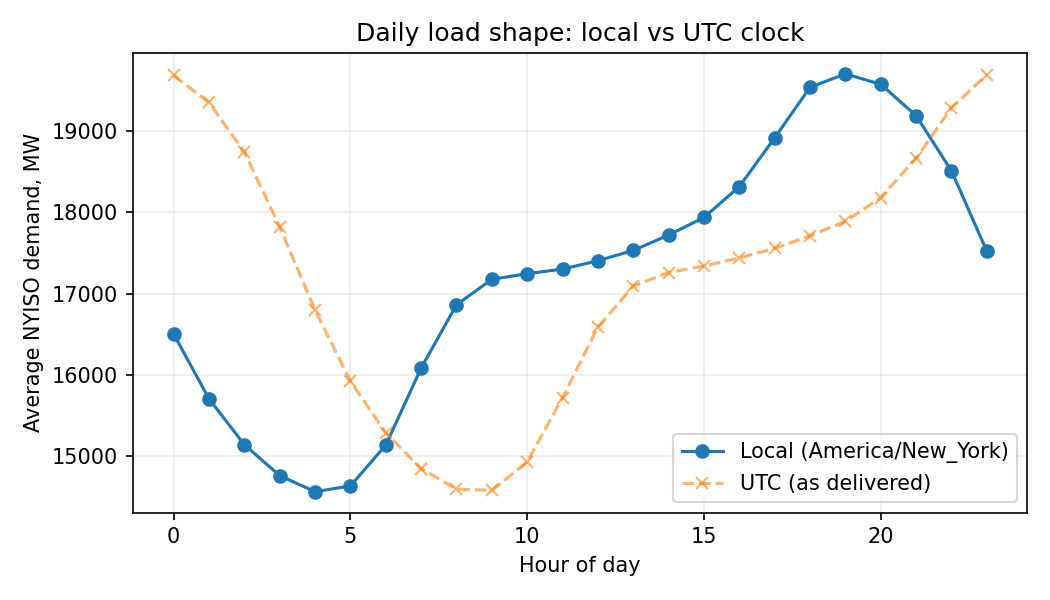

In [2]:
print(json.dumps(json.load(open('results/quality_report.json')), indent=2))
display(Image('charts/daily_shape.png'))

## Error analysis

In [3]:
pd.read_csv('results/error_analysis.csv', index_col=0).round(1)

,n_hours,baseline_168h,operator_DF,ridge,hgb
local hour: 0,1376,"1,311.800",396.300,787.400,516.400
local hour: 1,1386,"1,244.700",367.400,756.700,495.900
local hour: 2,1374,"1,198.700",357.200,731.800,476.100
local hour: 3,1378,"1,153.600",348.900,702.000,457.200
local hour: 4,1378,"1,127.500",344.700,668.000,437.300
local hour: 5,1378,"1,118.000",344.300,615.300,430.900
local hour: 6,1378,"1,131.500",357.800,522.300,438.900
local hour: 7,1378,"1,173.100",396.500,555.500,443.300
local hour: 8,1378,"1,237.200",425.500,725.400,510.300
local hour: 9,1378,"1,353.200",439.000,825.300,647.500


In [4]:
pd.read_csv('results/permutation_importance.csv').round(1)

,feature,mae_increase_MW,std
0,temp_f,"1,142.800",21.300
1,lag_48,581.900,3.600
2,hour,502.600,6.500
3,dow,199.400,14.600
4,lag_168,50.900,10.700
5,month,42.400,3.900
6,hdd,40.000,1.200
7,is_holiday,13.000,3.200
8,is_weekend,4.700,2.200
9,cdd,1.300,0.300


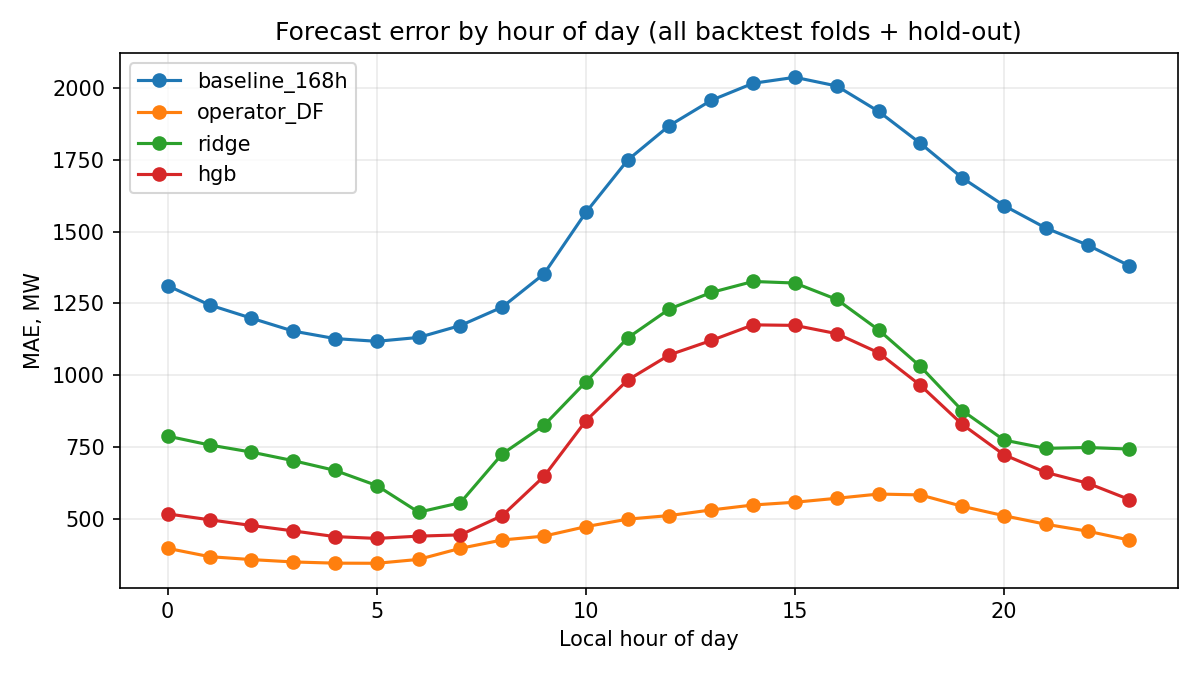

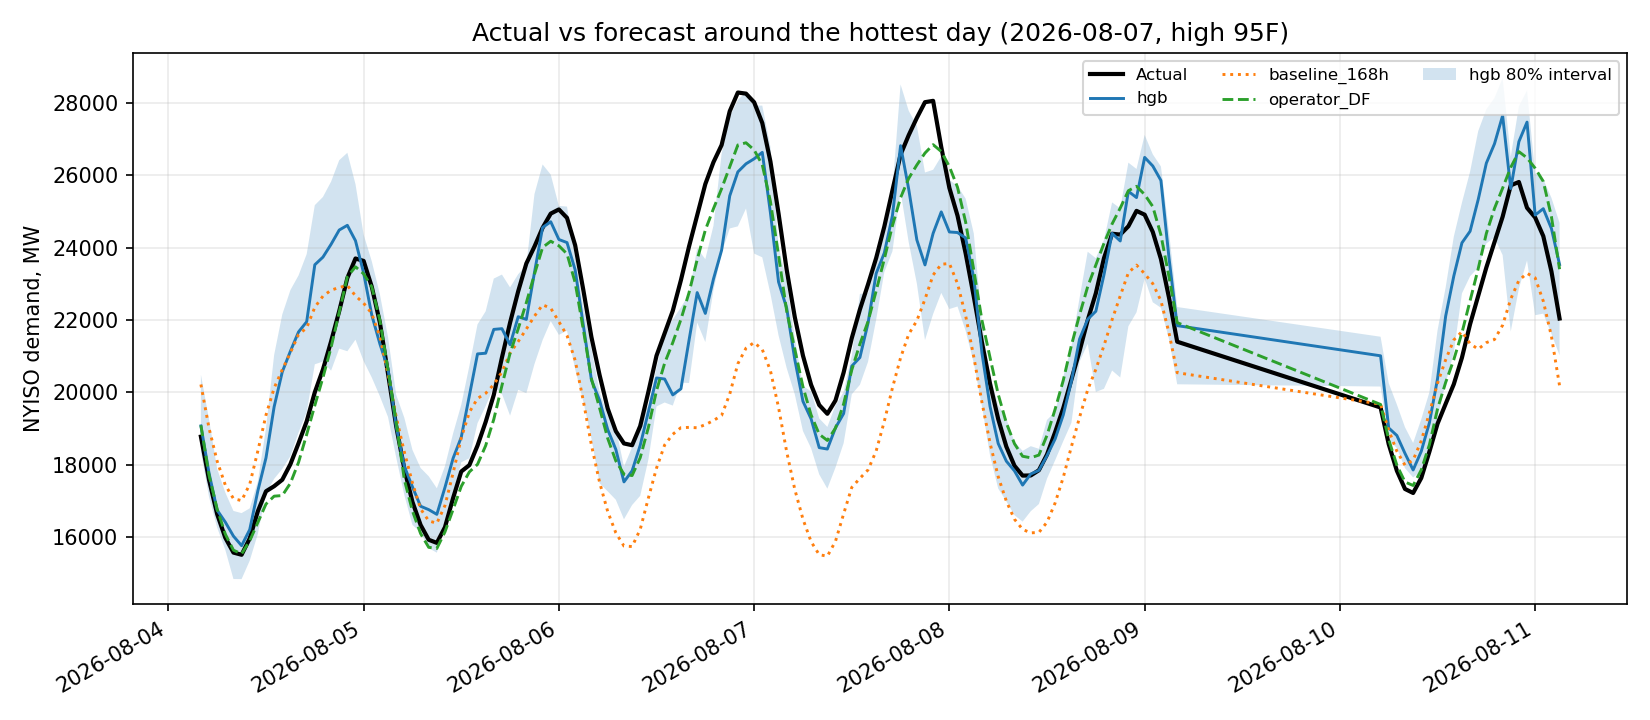

In [5]:
display(Image('charts/error_by_hour.png')); display(Image('charts/heatwave_week.png'))

## Prediction intervals

In [6]:
json.load(open('results/interval_coverage.json'))

{'nominal': 0.8,
 'holdout_coverage': 0.6595289079229122,
 'mean_width_MW': 2071.02179701029,
 'heat_wave_hours_in_holdout': 72,
 'heat_wave_coverage': 0.3194444444444444}